# Hito 1 - ETL Base INDICES Pregrado

En este notebook preparamos la base de matrícula de pregrado 2012-2026 y las dos fuentes externas que usamos (población del INE y titulados del SIES).

1. Preparación
2. Fuentes y carga de archivos
3. Base CNED: solo pregrado
4. Exploración inicial
5. Filtro de años y perfil de nulos
6. Nulos por sistema de admisión
7. Integración con la base del curso
8. Limpieza y transformación
9. Homologación de puntajes
10. Fuente externa 1: población INE
11. Fuente externa 2: titulados 2012-2025
12. Resumen de fuentes externas
13. Exportar
14. Diccionario de datos

## 1. Preparación

Librerías y ruta de la carpeta donde están los archivos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUTA = 'datos/'

## 2. Fuentes y carga de archivos

Todos los archivos están en la carpeta `datos/`. Esta es la lista con su origen y fecha de descarga.

| Archivo | Qué es | Dónde se descargó | Fecha de descarga |
|---|---|---|---|
| `01_BaseINDICES_Pregrado24.xlsx` | Base del curso, 2012–2022 | Entregada por el curso | No aplica |
| `Base-INDICES-Matricula-2005-2026.xlsx` | Base oficial INDICES del CNED, 2005–2026 | [cned.cl → Bases de datos](https://cned.cl/wp-content/uploads/2026/08/Base-INDICES-Matricula-2005-2026.xlsx) | 20/10/2026 |
| `ine_estimaciones-y-proyecciones-2002-2035_base-2017_region_area_tabulados.xlsx` | INE, estimaciones y proyecciones de población por región, 2002–2035 (base 2017) | [ine.gob.cl → Proyecciones de población → Cuadros estadísticos → Proyección base 2017](https://www.ine.gob.cl/docs/default-source/proyecciones-de-poblacion/cuadros-estadisticos/base-2017/ine_estimaciones-y-proyecciones-2002-2035_base-2017_region_area_tabulados.xlsx) | 19/10/2026 |
| `01_Esquema_Registro_Base_Pregrado.pdf` | Esquema de registro del CNED: qué significa cada columna | [cned.cl → Bases de datos](https://cned.cl/wp-content/uploads/2026/08/01_Esquema_Registro_Base_Pregrado.pdf) | 20/10/2026 |
| `TITULADO_2007-2025_web_27_05_2026_E-1.xlsx` | Titulados 2007–2025 por programa, SIES (base histórica) | [mifuturo.cl → Bases de datos → Titulación](https://www.mifuturo.cl/wp-content/uploads/2026/05/TITULADO_2007-2025_web_27_05_2026_E-1.xlsx) | 21/10/2026 |

In [2]:
# Base del curso (2012-2022)
base = pd.read_excel(RUTA + '01_BaseINDICES_Pregrado24.xlsx')

# Base oficial CNED (2005-2026)
cned = pd.read_excel(RUTA + 'Base-INDICES-Matricula-2005-2026.xlsx')

# INE: el archivo trae una hoja por región
ine_hojas = pd.read_excel(RUTA + 'ine_estimaciones-y-proyecciones-2002-2035_base-2017_region_area_tabulados.xlsx',
                          sheet_name=None, header=None)

# Titulados 2007-2025 (base histórica)
tit = pd.read_excel(RUTA + 'TITULADO_2007-2025_web_27_05_2026_E-1.xlsx')

print('Base del curso:', len(base), 'filas')
print('CNED:', len(cned), 'filas')
print('INE:', len(ine_hojas), 'hojas')
print('Titulados:', len(tit), 'filas')

Base del curso: 114265 filas
CNED: 260307 filas
INE: 18 hojas
Titulados: 234074 filas


## 3. Base CNED: solo pregrado

El archivo del CNED trae pregrado y posgrado, nos quedamos solo con pregrado.

In [3]:
df = cned[cned['Pregrado/Posgrado'] == 'Pregrado']
print('Pregrado:', len(df))

Pregrado: 215743


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 215743 entries, 0 to 215742
Data columns (total 62 columns):
 #   Column                                              Non-Null Count   Dtype  
---  ------                                              --------------   -----  
 0   Año                                                 215743 non-null  int64  
 1   Cód. Institución                                    215743 non-null  int64  
 2   Nombre Institución                                  215743 non-null  str    
 3   Tipo Institución                                    215743 non-null  str    
 4   Clasificación1                                      215743 non-null  str    
 5   Clasificación2                                      215743 non-null  str    
 6   Clasificación3                                      215743 non-null  str    
 7   Clasificación4                                      215743 non-null  str    
 8   Clasificación5                                      215743 non-null  str   

## 4. Exploración inicial

### 4.1 Regiones

Revisamos cómo vienen escritos los nombres de región. Hay algunos que hay que tener en cuenta al cruzar con el INE, por ejemplo `Región del Gral. B. O`Higgins` o `Región de los Ríos` con minúscula.

In [5]:
valores_unicos = df['Nombre Region'].unique()
print(valores_unicos)

<StringArray>
[         'Región Metropolitana',        'Región de La Araucanía',
            'Región del Bío-Bío',               'Región de Ñuble',
          'Región de Valparaíso',            'Región de los Ríos',
           'Región de Los Lagos',               'Región de Aysén',
         'Región de Antofagasta',            'Región de Coquimbo',
             'Región de Atacama',          'Región de Magallanes',
              'Región del Maule', 'Región del Gral. B. O`Higgins',
  'Región de Arica y Parinacota',            'Región de Tarapacá']
Length: 16, dtype: str


### 4.2 Ñuble y Biobío

Ñuble es región desde 2018. Revisamos qué comunas quedaron en cada una para ver si la base las separa bien.

In [6]:
comunas_nuble = df[df['Nombre Region'] == 'Región de Ñuble']['Comuna donde se imparte la carrera o programa'].unique()
print("Comunas del Ñuble: ", comunas_nuble)
comunas_bio = df[df['Nombre Region'] == 'Región del Bío-Bío']['Comuna donde se imparte la carrera o programa'].unique()
print("Comunas del Bío-Bío: ", comunas_bio)

Comunas del Ñuble:  <StringArray>
['Chillán', 'San Carlos', 'Portezuelo']
Length: 3, dtype: str
Comunas del Bío-Bío:  <StringArray>
[         'Concepción',         'Los Ángeles',          'Talcahuano',
              'Cañete', 'San Pedro de La Paz',              'Arauco',
          'Nacimiento',             'Hualpén',                'Lebu',
                'Lota',          'Los Alamos',               'Tirúa',
             'Cabrero',             'Coronel',         'Curanilahue']
Length: 15, dtype: str


### 4.3 Columnas disponibles

La base del CNED trae 62 columnas y la del curso 35.

In [7]:
list(df.columns)

['Año',
 'Cód. Institución',
 'Nombre Institución',
 'Tipo Institución',
 'Clasificación1',
 'Clasificación2',
 'Clasificación3',
 'Clasificación4',
 'Clasificación5',
 'Clasificación6',
 'Nombre de la Sede',
 'Comuna donde se imparte la carrera o programa',
 'Nombre Region',
 'Orden Geográfico de la Región (Norte aSur)',
 'Cód. Carrera',
 'Carrera Genérica',
 'Nombre Programa',
 'Mención o Especialidad',
 'Horario',
 'Tipo Programa',
 'Area Conocimiento',
 'idgenerocarrera',
 'Tipo Carrera',
 'IngresoDirecto',
 'Año Inicio Actividades',
 'Nombre del Campus',
 'Duración (en semestres)',
 'Cód. Campus',
 'Cód. Sede',
 'Título',
 'Grado Académico',
 'Máximo Puntaje (promedio matemáticas y lenguaje)',
 'Promedio Puntaje (promedio matemáticas y lenguaje)',
 'Mínimo Puntaje (promedio matemáticas y lenguaje)',
 'Puntaje de corte (primer seleccionado)',
 'Puntaje de corte (promedio de la carrera)',
 'Puntaje de corte (último seleccionado)',
 'Máximo Puntaje NEM',
 'Promedio Puntaje NEM',
 'Mí

### 4.4 Peso de los Institutos Profesionales

Porcentaje de filas que son IP.

In [8]:
total_entradas = len(df)
cantidad_ip = (df['Tipo Institución'] == 'I.P.').sum()
porcentaje_ip = (cantidad_ip / total_entradas) * 100

print(f"Total de entradas con 'I.P.': {cantidad_ip}")
print(f"Porcentaje del total: {porcentaje_ip:.2f}%")

Total de entradas con 'I.P.': 83109
Porcentaje del total: 38.52%


## 5. Filtro de años y perfil de nulos

Dejamos los años desde 2012, que es donde parte la base del curso.

In [9]:
df_2012 = df[df['Año'] >= 2012]
total_filas = len(df_2012)
print("Desde 2012: ", total_filas)

Desde 2012:  161505


Cantidad y porcentaje de nulos por columna (solo las que tienen alguno).

In [10]:
resumen_nulos = pd.DataFrame({
    'Valores Nulos': df_2012.isnull().sum(),
    'Porcentaje (%)': (df_2012.isnull().mean() * 100).round(2)
})

# Mostrar solo las columnas que tienen al menos un nulo (opcional)
display(resumen_nulos[resumen_nulos['Valores Nulos'] > 0])

,Valores Nulos,Porcentaje (%)
Mención o Especialidad,142400,88.17
Nombre del Campus,90161,55.83
Duración (en semestres),84,0.05
Cód. Campus,89620,55.49
Título,3320,2.06
Grado Académico,110148,68.20
Máximo Puntaje (promedio matemáticas y lenguaje),130584,80.85
Promedio Puntaje (promedio matemáticas y lenguaje),130602,80.87
Mínimo Puntaje (promedio matemáticas y lenguaje),130596,80.86
Puntaje de corte (primer seleccionado),132127,81.81


## 6. Nulos por sistema de admisión

La prueba de admisión cambió en el tiempo: PSU hasta 2020, PDT en 2021 y 2022, y PAES desde 2023. Por eso revisamos los nulos de cada período por separado.

In [11]:
df_PSU = df_2012[df_2012['Año'] <= 2020]
df_PDT = df_2012[df_2012['Año'].between(2021, 2022)]
df_PAES = df_2012[df_2012['Año'] >= 2023]

In [12]:
for nombre, d in [('PSU', df_PSU), ('PDT', df_PDT), ('PAES', df_PAES)]:
    print(nombre, ':', len(d), 'filas')
    resumen = pd.DataFrame({
        'Valores Nulos': d.isnull().sum(),
        'Porcentaje (%)': (d.isnull().mean() * 100).round(2)
    })
    display(resumen[resumen['Valores Nulos'] > 0])

PSU : 95022 filas


,Valores Nulos,Porcentaje (%)
Mención o Especialidad,82409,86.73
Nombre del Campus,54177,57.02
Duración (en semestres),84,0.09
Cód. Campus,54130,56.97
Título,1868,1.97
Grado Académico,65099,68.51
Máximo Puntaje (promedio matemáticas y lenguaje),76343,80.34
Promedio Puntaje (promedio matemáticas y lenguaje),76361,80.36
Mínimo Puntaje (promedio matemáticas y lenguaje),76350,80.35
Puntaje de corte (primer seleccionado),77620,81.69


PDT : 22537 filas


,Valores Nulos,Porcentaje (%)
Mención o Especialidad,20020,88.83
Nombre del Campus,12558,55.72
Cód. Campus,12546,55.67
Título,474,2.10
Grado Académico,15305,67.91
Máximo Puntaje (promedio matemáticas y lenguaje),18558,82.34
Promedio Puntaje (promedio matemáticas y lenguaje),18559,82.35
Mínimo Puntaje (promedio matemáticas y lenguaje),18558,82.34
Puntaje de corte (primer seleccionado),18706,83.00
Puntaje de corte (promedio de la carrera),18707,83.01


PAES : 43946 filas


,Valores Nulos,Porcentaje (%)
Mención o Especialidad,39971,90.95
Nombre del Campus,23426,53.31
Cód. Campus,22944,52.21
Título,978,2.23
Grado Académico,29744,67.68
Máximo Puntaje (promedio matemáticas y lenguaje),35683,81.20
Promedio Puntaje (promedio matemáticas y lenguaje),35682,81.20
Mínimo Puntaje (promedio matemáticas y lenguaje),35688,81.21
Puntaje de corte (primer seleccionado),35801,81.47
Puntaje de corte (promedio de la carrera),35800,81.46


## 7. Integración con la base del curso

La pauta pide completar la base del curso (2012-2022) con los años 2023 a 2026. Para 2012-2022 usamos la base del curso tal cual y del CNED solo tomamos 2023-2026.

Pasos:
1. Filtrar 2023-2026.
2. Sacar las instituciones de las Fuerzas Armadas y de Orden (ver 7.2).
3. Renombrar las columnas que cambian de nombre (ver 7.1).
4. Dejar las mismas 35 columnas de la base del curso, más `Códgo SIES` y `Cód. Institución`, que nos sirven para cruzar con titulados. En 2012-2022 estas dos quedan vacías porque la base del curso no las tiene.

In [13]:
# 1. Solo 2023-2026
nuevos = df[df['Año'].between(2023, 2026)]
print('2023-2026:', len(nuevos))

# 2. Sin instituciones de las Fuerzas Armadas y de Orden (F.F.A.A.)
nuevos = nuevos[nuevos['Tipo Institución'] != 'F.F.A.A.']
print('Sin F.F.A.A.:', len(nuevos))

# 3. Columnas que cambian de nombre
mapeo = {'Clasificación3': 'Acreditación',
         'Clasificación4': 'Autonomía',
         'Clasificación5': 'Gratuidad'}
nuevos = nuevos.rename(columns=mapeo)
print(nuevos[['Acreditación', 'Autonomía', 'Gratuidad']].drop_duplicates().head())

# 4. Mismas columnas + llaves, y unión
llaves = ['Códgo SIES', 'Cód. Institución']
print('Columnas que faltan:', [c for c in base.columns if c not in nuevos.columns])
integrada = pd.concat([base, nuevos[list(base.columns) + llaves]], ignore_index=True)
print('Total integrada:', len(integrada))

2023-2026: 43946
Sin F.F.A.A.: 43805
            Acreditación           Autonomía                   Gratuidad
0         (a) Acreditada        (a) Autónoma   (a) Adscritas a Gratuidad
1178      (a) Acreditada        (a) Autónoma  (b) No Adscritas/No Aplica
1811   (b) No Acreditada        (a) Autónoma  (b) No Adscritas/No Aplica
9205   (b) No Acreditada  (b) Licenciamiento  (b) No Adscritas/No Aplica
10100  (b) No Acreditada        (a) Autónoma   (a) Adscritas a Gratuidad
Columnas que faltan: []


Total integrada: 158070


In [14]:
integrada.groupby('Año').size()

Año
2012     9265
2013     9913
2014    10555
2015    10566
2016    10785
2017    10506
2018    10504
2019    10185
2020    10280
2021    10843
2022    10863
2023    11457
2024    10964
2025    10830
2026    10554
dtype: int64

### 7.1 Mapeo de columnas que cambian de nombre

| Base del curso (2012-2022) | CNED (2023-2026) | Nombre final |
|---|---|---|
| `Acreditación` | `Clasificación3` | `Acreditación` |
| `Autonomía` | `Clasificación4` | `Autonomía` |
| `Gratuidad` | `Clasificación5` | `Gratuidad` |

Hay que renombrarlas porque para unir las bases las columnas tienen que llamarse igual. Si no, quedan dos columnas separadas y cada una vacía en la mitad de los años.

Sabemos que son la misma variable por dos cosas. El esquema de registro del CNED (págs. 1 y 2) dice que `Clasificación 3` es acreditación, `Clasificación 4` autonomía y `Clasificación 5` gratuidad. Y los valores que toman en las dos bases son los mismos (celda de abajo).

In [15]:
for col in ['Acreditación', 'Autonomía', 'Gratuidad']:
    print(col)
    print('  Base del curso:', base[col].value_counts().to_dict())
    print('  CNED 2023-2026:', nuevos[col].value_counts().to_dict())

Acreditación
  Base del curso: {'(a) Acreditada': 95722, '(b) No Acreditada': 18543}
  CNED 2023-2026: {'(a) Acreditada': 39835, '(b) No Acreditada': 3970}
Autonomía
  Base del curso: {'(a) Autónoma': 113204, '(b) Licenciamiento': 688, '(d) Supervisión': 285, '(c) Examinación': 88}
  CNED 2023-2026: {'(a) Autónoma': 43696, '(e) Cerrada': 82, '(b) Licenciamiento': 27}
Gratuidad
  Base del curso: {'(b) No Adscritas/No Aplica': 66281, '(a) Adscritas a Gratuidad': 47984}
  CNED 2023-2026: {'(a) Adscritas a Gratuidad': 28577, '(b) No Adscritas/No Aplica': 15228}


Acreditación y Gratuidad tienen los mismos valores en las dos bases. En Autonomía aparece `(e) Cerrada` solo desde 2023 (instituciones en proceso de cierre); es una categoría oficial del esquema, así que la dejamos. `(c) Examinación` y `(d) Supervisión` no aparecen en 2023-2026 porque ninguna institución está en ese estado esos años.

### 7.2 Tipos de institución

El CNED tiene cuatro tipos de institución: Universidades (`Univ.`), Institutos Profesionales (`I.P.`), Centros de Formación Técnica (`C.F.T.`, incluye los estatales) e instituciones de las Fuerzas Armadas y de Orden (`F.F.A.A.`, por ejemplo la Academia de Ciencias Policiales de Carabineros o la Academia Politécnica Naval).

Nos quedamos con Universidades, Institutos Profesionales y Centros de Formación Técnica. Sacamos las de Fuerzas Armadas y de Orden por tres razones:
- La base del curso no las trae, aunque el CNED sí las tiene en esos años (72 filas en 2022). Si las dejamos solo desde 2023 aparece un tipo de institución nuevo y un salto en la serie que no es real.
- No son parte del sistema regular de educación superior. En el esquema del CNED tienen sus propias categorías de autonomía y subsistema, y no se comparan con el resto en acreditación, gratuidad o vacantes.
- Son muy pocas: 141 de 43.946 filas en 2023-2026 (0,3%).

In [16]:
print('Base del curso:', base['Tipo Institución'].value_counts().to_dict())
print('CNED 2023-2026, antes de filtrar:', df[df['Año'].between(2023, 2026)]['Tipo Institución'].value_counts().to_dict())
print('Base integrada:', integrada['Tipo Institución'].value_counts().to_dict())

ffaa = df[df['Año'].between(2023, 2026) & (df['Tipo Institución'] == 'F.F.A.A.')]
print('\nInstituciones de las Fuerzas Armadas y de Orden excluidas (2023-2026):')
for nombre in sorted(ffaa['Nombre Institución'].unique()):
    print(' -', nombre)

Base del curso: {'Univ.': 46758, 'I.P.': 46450, 'C.F.T.': 21057}
CNED 2023-2026, antes de filtrar: {'I.P.': 19693, 'Univ.': 16390, 'C.F.T.': 7722, 'F.F.A.A.': 141}


Base integrada: {'I.P.': 66143, 'Univ.': 63148, 'C.F.T.': 28779}

Instituciones de las Fuerzas Armadas y de Orden excluidas (2023-2026):
 - ACADEMIA DE CIENCIAS POLICIALES DE CARABINEROS DE CHILE
 - ACADEMIA NAC. EST. POLÍTICOS Y ESTRATÉGICOS ANEPE
 - ACADEMIA POLITÉCNICA AERONÁUTICA
 - ACADEMIA POLITÉCNICA NAVAL
 - ESC. DE ESPECIALIDADES SGTO 1º ADOLFO MENADIER ROJAS
 - ESC. DE GRUMETES ALEJANDRO NAVARRETE CISTERNA
 - ESCUELA DE AVIACIÓN
 - ESCUELA DE INVESTIGACIONES POLICIALES
 - ESCUELA MILITAR DEL GENERAL BERNARDO O'HIGGINS
 - ESCUELA NAVAL ARTURO PRAT
 - ESCUELA TÉCNICA AERONAUTICA


## 8. Limpieza y transformación

Aquí limpiamos la base integrada. No borramos ninguna fila; al final (8.4) revisamos que las filas y la matrícula por año sigan iguales.

### 8.1 Textos

Quitamos espacios al inicio, al final y espacios dobles en las columnas de texto que usamos para filtrar o cruzar. Si un texto queda vacío lo dejamos como nulo.

In [17]:
limpia = integrada.copy()

columnas_texto = ['Nombre Institución', 'Nombre de la Sede', 'Nombre Region', 'Carrera Genérica',
                  'Nombre Programa', 'Título', 'Grado Académico']

for col in columnas_texto:
    antes = limpia[col]
    limpia[col] = limpia[col].str.strip().str.replace(r'\s+', ' ', regex=True).replace('', np.nan)
    cambios = (antes.fillna('') != limpia[col].fillna('')).sum()
    print(f'{col}: {cambios} valores corregidos')

Nombre Institución: 420 valores corregidos
Nombre de la Sede: 2 valores corregidos


Nombre Region: 0 valores corregidos


Carrera Genérica: 3857 valores corregidos


Nombre Programa: 1889 valores corregidos


Título: 2752 valores corregidos
Grado Académico: 274 valores corregidos


### 8.2 Nombres de institución

La base del curso y el CNED escriben distinto algunas instituciones (por ejemplo "C.F.T. ALPES" y "CFT ALPES"). Si no lo arreglamos, la misma institución queda con dos nombres y su serie se corta en 2023. Dejamos el nombre como lo publica hoy el CNED:
- `C.F.T.` pasa a `CFT`
- `I.P.` pasa a `IP`
- `CFT ESTATAL` pasa a `CFTE` (CFT estatales)
- dos nombres largos se cambian por el actual (LAPLACE e INSALCO)

Todos los cambios quedan en la hoja "Puente instituciones" del diccionario.

In [18]:
nombres_actuales = {
    'CFT DE EST. SUP.Y CAPACITACIÓN PROFESIONAL LAPLACE': 'CFT LAPLACE',
    'CFT INSTITUTO SUPERIOR ALEMÁN DE COMERCIO INSALCO': 'CFT INSALCO',
}

def normalizar_institucion(nombres):
    return (nombres.str.strip().str.replace(r'\s+', ' ', regex=True)
            .str.replace(r'^C\.F\.T\. ', 'CFT ', regex=True)
            .str.replace(r'^I\.P\. ', 'IP ', regex=True)
            .str.replace(r'^CFT ESTATAL ', 'CFTE ', regex=True)
            .replace(nombres_actuales))

limpia['Nombre Institución'] = normalizar_institucion(limpia['Nombre Institución'])

puente_instituciones = (pd.DataFrame({'Nombre original': integrada['Nombre Institución'],
                                      'Nombre final': limpia['Nombre Institución']})
                        .drop_duplicates())
puente_instituciones = puente_instituciones[puente_instituciones['Nombre original'] != puente_instituciones['Nombre final']]
print('Nombres de institución cambiados:', len(puente_instituciones))

antiguas = set(limpia.loc[limpia['Año'] <= 2022, 'Nombre Institución'])
nuevas = set(limpia.loc[limpia['Año'] >= 2023, 'Nombre Institución'])
print('Instituciones de 2023-2026 que no aparecen en 2012-2022:', sorted(nuevas - antiguas))
print('Instituciones en total:', limpia['Nombre Institución'].nunique())

Nombres de institución cambiados: 120
Instituciones de 2023-2026 que no aparecen en 2012-2022: ['CFT ACADEMIA CHILENA DE YOGA', 'CFT ASISTE', 'IP CICERON', 'IP SAN SEBASTIÁN']
Instituciones en total: 183


Las que aparecen solo en 2023-2026 son instituciones nuevas o que no venían en la base del curso, no son errores de nombre.

### 8.3 Nulos

Antes de decidir qué hacer con los nulos revisamos dónde están. Lo que queremos saber es si el nulo es un dato que falta o si es algo que no aplica para ese programa.

In [19]:
p = 'Promedio Puntaje (promedio matemáticas y lenguaje)'

print('% de nulos en puntaje y vacantes según tipo de institución')
display((limpia[[p, 'Vacantes']].isna().groupby(limpia['Tipo Institución']).mean() * 100).round(1))

print('% de nulos en puntaje en universidades, según tipo de programa y horario')
u = limpia[limpia['Tipo Institución'] == 'Univ.']
display((u[p].isna().groupby([u['Tipo Programa'], u['Horario']]).mean() * 100).round(1).unstack())

print('Grado y título vacíos según tipo de carrera')
display(pd.DataFrame({'Grado vacío': limpia['Grado Académico'].isna().groupby(limpia['Tipo Carrera']).sum(),
                      'Título vacío': limpia['Título'].isna().groupby(limpia['Tipo Carrera']).sum()}))

% de nulos en puntaje y vacantes según tipo de institución


,Promedio Puntaje (promedio matemáticas y lenguaje),Vacantes
Tipo Institución,,
C.F.T.,99.8,17.8
I.P.,99.9,23.2
Univ.,51.8,27.5


% de nulos en puntaje en universidades, según tipo de programa y horario


Horario,Diurno,Otro,Vespertino
Tipo Programa,,,
Programa Especial,99.2,98.6,99.7
Programa Regular,33.3,90.5,89.4


Grado y título vacíos según tipo de carrera


,Grado vacío,Título vacío
Tipo Carrera,,
Bachillerato,12,583
Licenciatura,3,1666
Plan Común o Ciclo Básico,209,137
Profesional,38598,4
Profesional con Licenciatura,306,237
Técnico Nivel Superior,68870,0


Lo que vimos y lo que hacemos con cada uno:

- **Puntajes:** están vacíos en casi todos los CFT (99,8%) e IP (99,9%) y en los programas especiales (sobre 98%). En las universidades faltan en el 89% de los vespertinos regulares y solo en un tercio de los diurnos regulares. Estos programas no seleccionan por PSU, PDT o PAES, entonces el nulo significa "no aplica". Lo dejamos nulo y nunca 0 (el esquema del CNED, nota 2, también dice que los puntajes en cero se toman como nulos). Agregamos `tiene_puntaje` en la sección 9.
- **Vacantes:** hay nulos en los tres tipos de institución, más o menos parejo (entre 18% y 28%). Ahí el nulo es un dato que la institución no informó. Lo dejamos nulo, porque ponerle 0 sería decir que no hubo cupos.
- **Grado académico:** el vacío está casi todo en carreras técnicas y profesionales sin licenciatura, que no entregan grado. A esas les ponemos "No otorga grado académico" y a las demás "No informado".
- **Título:** el vacío está casi todo en licenciaturas, bachilleratos y planes comunes, que no entregan título profesional. A esas les ponemos "No otorga título profesional" y a las demás "No informado".
- **Duración:** no tiene nulos en la base integrada.

In [20]:
# Grado académico
no_otorga_grado = ['Técnico Nivel Superior', 'Profesional', 'Plan Común o Ciclo Básico']
sin_grado = limpia['Grado Académico'].isna()
limpia.loc[sin_grado & limpia['Tipo Carrera'].isin(no_otorga_grado), 'Grado Académico'] = 'No otorga grado académico'
limpia.loc[limpia['Grado Académico'].isna(), 'Grado Académico'] = 'No informado'

# Título
no_otorga_titulo = ['Licenciatura', 'Bachillerato', 'Plan Común o Ciclo Básico']
sin_titulo = limpia['Título'].isna()
limpia.loc[sin_titulo & limpia['Tipo Carrera'].isin(no_otorga_titulo), 'Título'] = 'No otorga título profesional'
limpia.loc[limpia['Título'].isna(), 'Título'] = 'No informado'

print('Grado:', limpia['Grado Académico'].value_counts().reindex(['No otorga grado académico', 'No informado']).to_dict())
print('Título:', limpia['Título'].value_counts().reindex(['No otorga título profesional', 'No informado']).to_dict())
print('Duración, nulos:', limpia['Duración (en semestres)'].isna().sum())
print(f"Vacantes informadas: {limpia['Vacantes'].notna().mean():.1%} de las filas")

Grado: {'No otorga grado académico': 107677, 'No informado': 321}
Título: {'No otorga título profesional': 2386, 'No informado': 241}
Duración, nulos: 0
Vacantes informadas: 76.0% de las filas


### 8.4 Control

Comparamos filas y matrícula total por año entre la fuente original y la base limpia. Tienen que ser iguales porque no borramos nada.

In [21]:
fuente = pd.concat([base, nuevos])
control = pd.DataFrame({
    'filas_fuente': fuente.groupby('Año').size(),
    'filas_limpia': limpia.groupby('Año').size(),
    'matricula_fuente': fuente.groupby('Año')['Matrícula Total'].sum(),
    'matricula_limpia': limpia.groupby('Año')['Matrícula Total'].sum(),
})
control['cuadra'] = (control['filas_fuente'] == control['filas_limpia']) & (control['matricula_fuente'] == control['matricula_limpia'])
print('Todo cuadra:', control['cuadra'].all())
control

Todo cuadra: True


,filas_fuente,filas_limpia,matricula_fuente,matricula_limpia,cuadra
Año,,,,,
2012,9265,9265,1014689,1014689,True
2013,9913,9913,1065938,1065938,True
2014,10555,10555,1111384,1111384,True
2015,10566,10566,1136366,1136366,True
2016,10785,10785,1154163,1154163,True
2017,10506,10506,1152459,1152459,True
2018,10504,10504,1167455,1167455,True
2019,10185,10185,1173587,1173587,True
2020,10280,10280,1134580,1134580,True


## 9. Homologación de puntajes

### 9.1 El quiebre

Los puntajes vienen de tres pruebas distintas según el año (nota 6 del esquema del CNED):

| Años | Prueba | Escala |
|---|---|---|
| 2012-2020 | PSU | 150 a 850 |
| 2021-2022 | PDT | 150 a 850 |
| 2023-2026 | PAES | 100 a 1000 |

Hay 6 columnas de puntaje. Las tres de "promedio matemáticas y lenguaje" (máximo, promedio y mínimo) son el promedio de esas dos pruebas de los alumnos de primer año que entraron por PSU, PDT o PAES. Las tres de "puntaje de corte" son el puntaje ponderado (pruebas, NEM y ranking con los pesos de cada carrera) del primer seleccionado, el promedio de la carrera y el último seleccionado.

Como la escala cambia, un mismo número no significa lo mismo en PSU que en PAES.

### 9.2 Marca del sistema de admisión

A cada fila le agregamos `sistema_admision` según el año, y `tiene_puntaje` para saber si el programa informó puntaje.

In [22]:
limpia['sistema_admision'] = np.select([limpia['Año'] <= 2020, limpia['Año'] <= 2022], ['PSU', 'PDT'], default='PAES')
limpia['tiene_puntaje'] = limpia['Promedio Puntaje (promedio matemáticas y lenguaje)'].notna()

limpia.groupby('sistema_admision').agg(filas=('Año', 'size'),
                                       años=('Año', lambda a: f'{a.min()}-{a.max()}'),
                                       con_puntaje=('tiene_puntaje', 'mean')).round(3)

,filas,años,con_puntaje
sistema_admision,,,
PAES,43805,2023-2026,0.189
PDT,21706,2021-2022,0.181
PSU,92559,2012-2020,0.198


### 9.3 El quiebre en los datos

Puntaje por año: cuántos programas tienen puntaje, el promedio, el mínimo y el máximo.

In [23]:
puntaje = 'Promedio Puntaje (promedio matemáticas y lenguaje)'
corte = 'Puntaje de corte (primer seleccionado)'

evidencia = (limpia.groupby(['Año', 'sistema_admision'])
             .agg(programas_con_puntaje=(puntaje, 'count'),
                  promedio=(puntaje, 'mean'),
                  minimo=(puntaje, 'min'),
                  maximo=(puntaje, 'max'),
                  corte_maximo=(corte, 'max'))
             .round(0))
evidencia

,,programas_con_puntaje,promedio,minimo,maximo,corte_maximo
Año,sistema_admision,,,,,
2012,PSU,2188,551.0,291.0,817.0,837.0
2013,PSU,2084,556.0,284.0,784.0,839.0
2014,PSU,1881,564.0,396.0,779.0,840.0
2015,PSU,2092,553.0,266.0,789.0,850.0
2016,PSU,1929,564.0,392.0,781.0,831.0
2017,PSU,1938,563.0,406.0,787.0,880.0
2018,PSU,2016,559.0,369.0,796.0,850.0
2019,PSU,2105,554.0,339.0,786.0,860.0
2020,PSU,2131,554.0,359.0,784.0,880.0


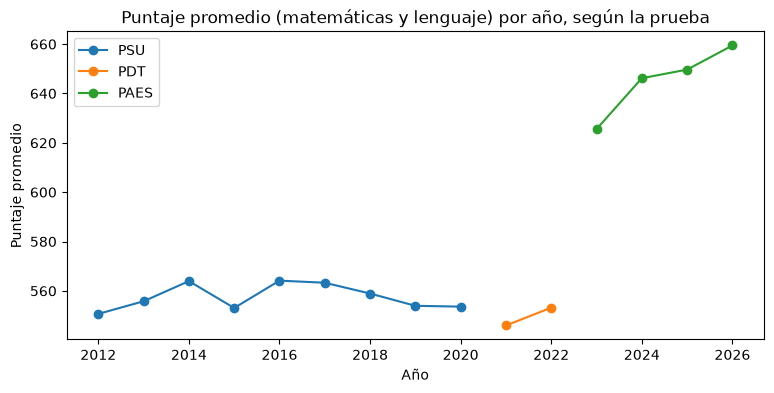

In [24]:
serie = limpia.groupby('Año')[puntaje].mean()

fig, ax = plt.subplots(figsize=(9, 4))
for sistema, color in [('PSU', 'tab:blue'), ('PDT', 'tab:orange'), ('PAES', 'tab:green')]:
    años = sorted(limpia.loc[limpia['sistema_admision'] == sistema, 'Año'].unique())
    ax.plot(años, serie.loc[años], marker='o', color=color, label=sistema)
ax.set_title('Puntaje promedio (matemáticas y lenguaje) por año, según la prueba')
ax.set_xlabel('Año')
ax.set_ylabel('Puntaje promedio')
ax.legend()
plt.show()

En PSU y PDT (2012-2022) el promedio anda entre 546 y 564 y el máximo no pasa de 817. Con la PAES (2023-2026) el promedio sube a 626-659 y el máximo llega a 961. Ese salto de casi 70 puntos en 2023 no es que los alumnos hayan mejorado, es el cambio de escala, y por eso no se pueden juntar los años sin tratamiento. El corte máximo a veces pasa un poco el tope (880 en PSU, 1.020 en PAES), probablemente por bonificaciones que dan algunas carreras.

### 9.4 Decisión

La pauta da tres opciones: series separadas, normalizar o excluir.
- Normalizar (por ejemplo a percentiles dentro de cada año) permitiría comparar entre pruebas, pero el valor deja de ser un puntaje y supone que las pruebas miden lo mismo.
- Excluir es lo más fácil, pero perdemos toda la información de 2012-2022.
- Series separadas deja los puntajes como los publica el CNED; solo hay que cuidar no mezclar sistemas.

Elegimos series separadas. Ninguna de nuestras preguntas compara puntajes entre años, así que no necesitamos una escala común y así no inventamos valores.

### 9.5 Cómo usamos los puntajes desde aquí

- Siempre filtrados por un solo `sistema_admision`.
- No se suman, se promedian (ojalá ponderando por matrícula de primer año).
- Solo con las filas que tienen `tiene_puntaje = True`.

## 10. Fuente externa 1: población INE

El archivo del INE trae una hoja por región. En cada hoja la fila 5 tiene los años y la fila 7 ("Ambos sexos") la población total. Lo pasamos a una tabla con una fila por región y año.

Sobre Ñuble: el INE (base 2017) la trae separada en todos los años y la base de matrícula también la tiene separada desde 2012, así que las dos fuentes coinciden y no hay que juntar Ñuble con Biobío.

In [25]:
filas = []
for hoja, t in ine_hojas.items():
    if hoja in ('Presentación', 'Nacional'):
        continue
    assert t.iloc[6, 0] == 'Ambos sexos'
    anios = t.iloc[4, 1:].astype(int)
    poblacion = pd.to_numeric(t.iloc[6, 1:])
    for a, p in zip(anios, poblacion):
        filas.append({'hoja': hoja, 'Año': a, 'Poblacion': p})

ine = pd.DataFrame(filas)
ine = ine[ine['Año'].between(2012, 2026)]
print(len(ine), 'filas,', ine['hoja'].nunique(), 'regiones')

240 filas, 16 regiones


Tabla puente entre el nombre de la hoja del INE y el nombre de la región en la base.

In [26]:
puente_region = {
    'Arica y Parinacota': 'Región de Arica y Parinacota',
    'Tarapacá': 'Región de Tarapacá',
    'Antofagasta': 'Región de Antofagasta',
    'Atacama': 'Región de Atacama',
    'Coquimbo': 'Región de Coquimbo',
    'Valparaíso': 'Región de Valparaíso',
    'Metropolitana': 'Región Metropolitana',
    "O'Higgins": 'Región del Gral. B. O`Higgins',
    'Maule': 'Región del Maule',
    'Ñuble': 'Región de Ñuble',
    'Biobío': 'Región del Bío-Bío',
    'La Araucanía': 'Región de La Araucanía',
    'Los Ríos': 'Región de los Ríos',
    'Los Lagos': 'Región de Los Lagos',
    'Aysén': 'Región de Aysén',
    'Magallanes': 'Región de Magallanes',
}
ine['Nombre Region'] = ine['hoja'].map(puente_region)
print('Hojas sin puente:', ine.loc[ine['Nombre Region'].isna(), 'hoja'].unique())

regiones_base = limpia['Nombre Region'].drop_duplicates()
print('Regiones de la base que cruzan:', regiones_base.isin(ine['Nombre Region']).sum(), 'de', len(regiones_base))

Hojas sin puente: <StringArray>
[]
Length: 0, dtype: str
Regiones de la base que cruzan: 16 de 16


Matrícula por cada 1.000 habitantes, por región y año. Ojo: la matrícula se cuenta donde está la sede y no donde vive el estudiante, así que esto mide cuánta matrícula se concentra en la región, no cobertura.

In [27]:
mat_region = limpia.groupby(['Nombre Region', 'Año'], as_index=False)['Matrícula Total'].sum()
regional = mat_region.merge(ine[['Nombre Region', 'Año', 'Poblacion']], on=['Nombre Region', 'Año'], how='left')
regional['Matricula_x1000_hab'] = regional['Matrícula Total'] / regional['Poblacion'] * 1000

regional.pivot(index='Nombre Region', columns='Año', values='Matricula_x1000_hab')[[2012, 2026]].round(1).sort_values(2026)

Año,2012,2026
Nombre Region,,
Región de Aysén,13.9,26.3
Región del Gral. B. O`Higgins,24.1,30.6
Región de Atacama,33.5,39.1
Región de Magallanes,38.5,41.9
Región de Ñuble,43.6,43.7
Región de Los Lagos,37.0,50.0
Región de Tarapacá,49.0,50.0
Región de Antofagasta,58.6,51.7
Región del Maule,43.6,53.2


## 11. Fuente externa 2: titulados 2012-2025

Usamos la base histórica de titulados del SIES. Nos quedamos con pregrado y con los años 2012 a 2025 (los titulados de 2026 todavía no se publican). El cruce lo hacemos por institución y año, usando el código de institución del SIES.

In [28]:
tit = tit[tit['NIVEL GLOBAL'] == 'Pregrado'].copy()
tit['Año'] = tit['AÑO'].str[4:].astype(int)      # 'TIT_2025' pasa a 2025
tit = tit[tit['Año'].between(2012, 2025)]
print('Titulados de pregrado 2012-2025:', len(tit), 'filas')

tit_inst = tit.groupby(['CÓDIGO INSTITUCIÓN', 'Año'], as_index=False)['TOTAL TITULACIONES'].sum()
tit_inst.groupby('Año')['TOTAL TITULACIONES'].sum()

Titulados de pregrado 2012-2025: 144542 filas


Año
2012    135721
2013    156991
2014    171648
2015    189086
2016    197568
2017    206554
2018    209022
2019    201142
2020    160891
2021    228693
2022    225942
2023    231203
2024    226341
2025    238716
Name: TOTAL TITULACIONES, dtype: int64

### 11.1 Tabla puente: institución a código SIES

La base del curso no trae códigos, pero el archivo del CNED sí trae el código SIES de cada programa en todos los años (el número después de la I, por ejemplo en `I70S1C1J1V2`, es la institución). Como en la 8.2 ya dejamos los nombres de institución iguales a los del CNED, armamos la tabla puente nombre a código con el CNED. Si una institución tiene programas con distintos códigos (le pasa a la U. Bolivariana, que tiene algunos programas con códigos de otras instituciones), nos quedamos con el que más se repite.

Hay 26 instituciones que el CNED nunca registra con código (por ejemplo el CFT INACAP). A 24 las encontramos por nombre en el archivo de titulados y les pusimos el código a mano. CFT ACCIOMA e IP CIISA no aparecen en titulados.

In [29]:
cned_cod = df[df['Año'].between(2012, 2026) & (df['Tipo Institución'] != 'F.F.A.A.')].copy()
cned_cod['Nombre Institución'] = normalizar_institucion(cned_cod['Nombre Institución'])
cned_cod['cod_inst'] = cned_cod['Códgo SIES'].str.extract(r'^I(\d+)S')[0].astype(float)
puente_cod = cned_cod.dropna(subset=['cod_inst']).groupby('Nombre Institución')['cod_inst'].agg(lambda s: s.mode().iloc[0])

# Instituciones sin código en el CNED: código buscado por nombre en titulados
codigos_a_mano = {
    'CFT ACADEMIA CHILENA DE YOGA': 959,
    'CFT BARROS ARANA': 258,
    'CFT CENTRO DE ENS. ALTA COSTURA PAULINA DIARD': 229,
    'CFT CENTRO TECNOLÓGICO SUPERIOR INFOMED': 236,
    'CFT CEPA DE LA III REGIÓN': 254,
    'CFT CRECIC': 314,
    'CFT ESC. DE INTÉRPRETES INCENI': 230,
    'CFT ESPERANZA JOVEN': 637,
    'CFT FINNING': 782,
    'CFT ICCE': 214,
    'CFT INACAP': 430,
    'CFT INSALCO': 241,
    'CFT INSEC': 206,
    'CFT INST. SUPERIOR DE ESTUDIOS JURÍDICOS CANON': 328,
    'CFT JORGE ALVAREZ ECHEVERRÍA': 339,
    'CFT LAPLACE': 427,
    'CFTE DE ATACAMA': 909,                       # CFT DE LA REGION DE ATACAMA
    'CFTE DE COQUIMBO': 910,                      # CFT DE LA REGION DE COQUIMBO
    'CFTE DEL MAULE': 914,                        # CFT DE LA REGION DEL MAULE
    'IP CHILENO BRITÁNICO': 108,                  # IP CHILENO BRITANICO DE CULTURA
    'IP CICERON': 951,
    'IP ENAC': 133,
    'IP ESCUELA DE MARINA MERCANTE PILOTO PARDO': 754,
    'U. DEL MAR': 27,
}
puente_cod = pd.concat([puente_cod, pd.Series(codigos_a_mano, dtype=float)])
assert not puente_cod.index.duplicated().any()

instituciones = pd.Series(limpia['Nombre Institución'].unique())
puente_cod = puente_cod[puente_cod.index.isin(instituciones)]
print('Instituciones de la base:', len(instituciones), '| con código:', len(puente_cod))
print('Sin código:', sorted(set(instituciones) - set(puente_cod.index)))
print('Códigos repetidos entre instituciones:', puente_cod.duplicated().sum())

nombres_tit = tit.groupby('CÓDIGO INSTITUCIÓN')['NOMBRE INSTITUCIÓN'].agg(lambda s: s.mode().iloc[0])
puente_titulados = pd.DataFrame({'Nombre Institución (base)': puente_cod.index,
                                 'Código SIES institución': puente_cod.values.astype(int)})
puente_titulados['Origen del código'] = np.where(puente_titulados['Nombre Institución (base)'].isin(list(codigos_a_mano)),
                                                 'Buscado por nombre en titulados', 'Código SIES del CNED')
puente_titulados['Nombre en titulados'] = puente_titulados['Código SIES institución'].map(nombres_tit)
puente_titulados[puente_titulados['Origen del código'] == 'Buscado por nombre en titulados']

Instituciones de la base: 183 | con código: 181
Sin código: ['CFT ACCIOMA', 'IP CIISA']
Códigos repetidos entre instituciones: 0


,Nombre Institución (base),Código SIES institución,Origen del código,Nombre en titulados
157,CFT ACADEMIA CHILENA DE YOGA,959,Buscado por nombre en titulados,CFT ACADEMIA CHILENA DE YOGA
158,CFT BARROS ARANA,258,Buscado por nombre en titulados,CFT BARROS ARANA
159,CFT CENTRO DE ENS. ALTA COSTURA PAULINA DIARD,229,Buscado por nombre en titulados,CFT CENTRO DE ENSEÑANZA DE ALTA COSTURA PAULIN...
160,CFT CENTRO TECNOLÓGICO SUPERIOR INFOMED,236,Buscado por nombre en titulados,CFT CENTRO TECNOLOGICO SUPERIOR INFOMED
161,CFT CEPA DE LA III REGIÓN,254,Buscado por nombre en titulados,CFT CEPA DE LA III REGION
162,CFT CRECIC,314,Buscado por nombre en titulados,CFT CRECIC
163,CFT ESC. DE INTÉRPRETES INCENI,230,Buscado por nombre en titulados,CFT ESCUELA DE INTERPRETES INCENI
164,CFT ESPERANZA JOVEN,637,Buscado por nombre en titulados,CFT ESPERANZA JOVEN
165,CFT FINNING,782,Buscado por nombre en titulados,CFT FINNING
166,CFT ICCE,214,Buscado por nombre en titulados,CFT INSTITUTO CENTRAL DE CAPACITACION EDUCACIO...


### 11.2 Cruce por institución y año

Sumamos la matrícula por institución y año, le ponemos el código con la tabla puente y la juntamos con los titulados del mismo año.

In [30]:
mat_inst = (limpia[limpia['Año'] <= 2025]
            .groupby(['Nombre Institución', 'Tipo Institución', 'Año'], as_index=False)['Matrícula Total'].sum())
mat_inst['cod_inst'] = mat_inst['Nombre Institución'].map(puente_cod)

inst = mat_inst.merge(tit_inst, left_on=['cod_inst', 'Año'], right_on=['CÓDIGO INSTITUCIÓN', 'Año'], how='left')
inst['Titulados_x100_matriculados'] = inst['TOTAL TITULACIONES'] / inst['Matrícula Total'] * 100
inst['cruza'] = inst['TOTAL TITULACIONES'].notna()

total_tit_año = tit_inst.groupby('Año')['TOTAL TITULACIONES'].sum()
cobertura = inst.groupby('Año').agg(instituciones=('cruza', 'size'), cruzan=('cruza', 'sum'))
cobertura['matricula_cubierta_%'] = (inst[inst['cruza']].groupby('Año')['Matrícula Total'].sum()
                                     / inst.groupby('Año')['Matrícula Total'].sum() * 100)
cobertura['titulados_en_el_cruce_%'] = inst.groupby('Año')['TOTAL TITULACIONES'].sum() / total_tit_año * 100
cobertura.round(1)

,instituciones,cruzan,matricula_cubierta_%,titulados_en_el_cruce_%
Año,,,,
2012,156,146,99.8,99.2
2013,151,145,99.8,97.4
2014,147,140,99.8,98.1
2015,139,132,99.8,98.5
2016,135,130,99.9,98.6
2017,133,128,99.8,99.3
2018,135,126,99.7,99.4
2019,130,121,99.6,99.7
2020,130,115,99.1,98.9


### 11.3 Qué hacemos con los que no cruzan

In [31]:
no_cruzan = inst[~inst['cruza']]
print('Institución-año sin titulados:', len(no_cruzan), 'de', len(inst))
print(no_cruzan.groupby('Nombre Institución')['Año'].agg(lambda a: f'{a.min()}-{a.max()}').to_string())

claves_base = set(zip(inst['cod_inst'], inst['Año']))
fuera = tit_inst[[(c, a) not in claves_base for c, a in zip(tit_inst['CÓDIGO INSTITUCIÓN'], tit_inst['Año'])]]
print(f"\nTitulados de instituciones que no tienen matrícula ese año en la base: {fuera['TOTAL TITULACIONES'].sum() / tit_inst['TOTAL TITULACIONES'].sum():.1%}")

Institución-año sin titulados: 96 de 1856
Nombre Institución
CFT ACADEMIA CHILENA DE YOGA                   2024-2024
CFT ACCIOMA                                    2012-2022
CFT ALFA                                       2012-2017
CFT BARROS ARANA                               2015-2015
CFT CEPA DE LA III REGIÓN                      2012-2014
CFT DE LA INDUSTRIA GRÁFICA O C.F.T. INGRAF    2012-2012
CFT ESCUELA CULINARIA FRANCESA                 2012-2020
CFT FINNING                                    2014-2018
CFT JORGE ALVAREZ ECHEVERRÍA                   2012-2012
CFT LOS LAGOS                                  2023-2023
CFT LUIS ALBERTO VERA                          2016-2016
CFT TEODORO WICKEL                             2025-2025
CFTE DE ANTOFAGASTA                            2020-2021
CFTE DE ATACAMA                                2021-2022
CFTE DE AYSÉN                                  2022-2023
CFTE DE COQUIMBO                               2019-2020
CFTE DE LA ARAUCANÍA       

- **Institución y año sin titulados:** queda vacío, no 0. Pasa con instituciones nuevas que todavía no titulan, con las que están cerrando o con las que no informaron, y no podemos saber cuál de esas es.
- **Titulados de instituciones que no tienen matrícula ese año en la base:** son instituciones cerradas, carreras en convenio o instituciones que no venían en la base del curso. Sin matrícula no se puede calcular el indicador, así que no entran.
- **CFT ACCIOMA e IP CIISA:** no tienen código ni aparecen en titulados, quedan vacías.

### 11.4 Titulados por cada 100 matriculados

Con las instituciones que cruzan, calculamos titulados por cada 100 matriculados por tipo de institución y año.

Ojo al leerlo: en instituciones que están cerrando (por ejemplo la U. Tecnológica de Chile INACAP) el indicador puede pasar de 100, porque casi no tienen matrícula pero siguen titulando a los alumnos que ya estaban.

In [32]:
c = inst[inst['cruza']]
serie_tit = c.groupby(['Año', 'Tipo Institución'])[['TOTAL TITULACIONES', 'Matrícula Total']].sum()
serie_tit['Titulados_x100'] = serie_tit['TOTAL TITULACIONES'] / serie_tit['Matrícula Total'] * 100
serie_tit['Titulados_x100'].unstack().round(1)

Tipo Institución,C.F.T.,I.P.,Univ.
Año,,,
2012,19.4,13.8,11.8
2013,19.7,15.2,12.8
2014,18.8,16.5,13.6
2015,20.6,18.7,14.1
2016,23.3,19.8,13.8
2017,24.2,21.5,14.4
2018,26.1,21.7,14.1
2019,25.4,19.8,14.0
2020,19.0,17.6,11.3


## 12. Resumen de fuentes externas

Para cada fuente: de dónde sale, el grano, la llave con la que cruzamos, la tabla puente, cuánto cruza y qué pasa con lo que no cruza. Esta misma tabla queda en el diccionario.

In [33]:
regiones_cruzan = regiones_base.isin(ine['Nombre Region']).sum()

resumen_fuentes = pd.DataFrame([
    {'Fuente': 'Estimaciones y proyecciones de población 2002-2035, base 2017',
     'Publica': 'INE',
     'Archivo': 'ine_estimaciones-y-proyecciones-2002-2035_base-2017_region_area_tabulados.xlsx',
     'URL': 'https://www.ine.gob.cl/docs/default-source/proyecciones-de-poblacion/cuadros-estadisticos/base-2017/ine_estimaciones-y-proyecciones-2002-2035_base-2017_region_area_tabulados.xlsx',
     'Fecha de descarga': '19/10/2026',
     'Años usados': '2012-2026',
     'Grano original': 'Una hoja por región, con los años en columnas',
     'Grano final': 'Una fila por región y año',
     'Llave de cruce': 'Nombre Region + Año',
     'Tabla puente': 'Puente regiones (nombre de la hoja del INE a nombre de región de la base)',
     'Coincidencia': f'{regiones_cruzan} de {len(regiones_base)} regiones',
     'Lo que no cruza': 'Nada, cruzan todas las regiones',
     'Pregunta': 'P2: matrícula respecto al tamaño de la población de la región'},
    {'Fuente': 'Base histórica de titulados 2007-2025',
     'Publica': 'SIES, Mineduc (mifuturo.cl)',
     'Archivo': 'TITULADO_2007-2025_web_27_05_2026_E-1.xlsx',
     'URL': 'https://www.mifuturo.cl/wp-content/uploads/2026/05/TITULADO_2007-2025_web_27_05_2026_E-1.xlsx',
     'Fecha de descarga': '21/10/2026',
     'Años usados': '2012-2025',
     'Grano original': 'Una fila por programa (código SIES) y año',
     'Grano final': 'Una fila por institución y año',
     'Llave de cruce': 'Código de institución SIES + Año',
     'Tabla puente': 'Puente titulados (nombre de institución a código SIES; 24 instituciones buscadas por nombre)',
     'Coincidencia': (f"Matrícula cubierta entre {cobertura['matricula_cubierta_%'].min():.1f}% y {cobertura['matricula_cubierta_%'].max():.1f}% según el año; "
                      f"titulados en el cruce entre {cobertura['titulados_en_el_cruce_%'].min():.1f}% y {cobertura['titulados_en_el_cruce_%'].max():.1f}%"),
     'Lo que no cruza': 'Institución-año sin titulados queda vacío (no 0). Titulados de instituciones sin matrícula ese año (cerradas o en convenio) no entran.',
     'Pregunta': 'P4: titulados en relación a la matrícula de cada institución'},
])
with pd.option_context('display.max_colwidth', None):
    display(resumen_fuentes.T)

,0,1
Fuente,"Estimaciones y proyecciones de población 2002-2035, base 2017",Base histórica de titulados 2007-2025
Publica,INE,"SIES, Mineduc (mifuturo.cl)"
Archivo,ine_estimaciones-y-proyecciones-2002-2035_base-2017_region_area_tabulados.xlsx,TITULADO_2007-2025_web_27_05_2026_E-1.xlsx
URL,https://www.ine.gob.cl/docs/default-source/proyecciones-de-poblacion/cuadros-estadisticos/base-2017/ine_estimaciones-y-proyecciones-2002-2035_base-2017_region_area_tabulados.xlsx,https://www.mifuturo.cl/wp-content/uploads/2026/05/TITULADO_2007-2025_web_27_05_2026_E-1.xlsx
Fecha de descarga,19/10/2026,21/10/2026
Años usados,2012-2026,2012-2025
Grano original,"Una hoja por región, con los años en columnas",Una fila por programa (código SIES) y año
Grano final,Una fila por región y año,Una fila por institución y año
Llave de cruce,Nombre Region + Año,Código de institución SIES + Año
Tabla puente,Puente regiones (nombre de la hoja del INE a nombre de región de la base),Puente titulados (nombre de institución a código SIES; 24 instituciones buscadas por nombre)


## 13. Exportar

Guardamos las tablas finales en `salida/` para cargarlas después al DataMart.

In [34]:
import os
os.makedirs('salida', exist_ok=True)

limpia.to_csv('salida/base_pregrado_2012_2026.csv', index=False, encoding='utf-8-sig')
ine[['Nombre Region', 'Año', 'Poblacion']].to_csv('salida/poblacion_ine_region_anio.csv', index=False, encoding='utf-8-sig')
inst.to_csv('salida/titulados_por_institucion_2012_2025.csv', index=False, encoding='utf-8-sig')

for archivo in sorted(os.listdir('salida')):
    print(archivo)

Diccionario_datos.xlsx
base_pregrado_2012_2026.csv
poblacion_ine_region_anio.csv
titulados_por_institucion_2012_2025.csv


## 14. Diccionario de datos

Armamos un Excel (`salida/Diccionario_datos.xlsx`) con estas hojas:
- Diccionario base: cada columna con su nombre original en 2012-2022 y en 2023-2026, nombre final, tipo, descripción y regla de transformación. Las descripciones las sacamos del esquema de registro del CNED.
- Nombres por año: el nombre original de cada columna en cada año.
- Fuentes externas: las columnas que usamos del INE y de titulados.
- Resumen fuentes: la tabla de la sección 12.
- Puente regiones, Puente instituciones y Puente titulados: las tablas puente.

En general, 2012-2022 viene de la base del curso y 2023-2026 del CNED (solo pregrado y sin Fuerzas Armadas y de Orden).

In [35]:
mapeo_inverso = {v: k for k, v in mapeo.items()}

desc = {
 'Año': ('Año del proceso INDICES. Los datos tienen cierre al 30 de abril de cada año.', 'Sin cambios.'),
 'Nombre Institución': ('Nombre de la institución de educación superior.', 'Espacios corregidos. Siglas homologadas (C.F.T. a CFT, I.P. a IP, CFT ESTATAL a CFTE) y dos nombres largos llevados al nombre actual. Ver Puente instituciones.'),
 'Tipo Institución': ('Tipo de institución: Univ. (Universidad), I.P. (Instituto Profesional), C.F.T. (Centro de Formación Técnica).', 'Se excluyen las instituciones de las Fuerzas Armadas y de Orden (F.F.A.A.) en 2023-2026.'),
 'Clasificación2': ('Clasificación de la institución: estatales CRUCH, privadas CRUCH, privadas, IP, CFT, CFT estatales.', 'Sin cambios. Según el CNED (nota 7) se actualizó hasta 2020; los años siguientes repiten 2020.'),
 'Acreditación': ('Acreditación institucional: Acreditada / No Acreditada.', 'En 2023-2026 se renombra desde Clasificación3.'),
 'Autonomía': ('Situación de autonomía: Autónoma, Licenciamiento, Examinación, Supervisión, Cerrada.', 'En 2023-2026 se renombra desde Clasificación4. La categoría Cerrada aparece solo desde 2023.'),
 'Gratuidad': ('Adscripción a gratuidad: Adscritas / No Adscritas.', 'En 2023-2026 se renombra desde Clasificación5.'),
 'Nombre de la Sede': ('Ciudad donde se dicta el programa.', 'Espacios corregidos.'),
 'Nombre Region': ('Región donde se dicta el programa (no la región donde vive el estudiante).', 'Espacios corregidos. Se cruza con el INE mediante Puente regiones.'),
 'Carrera Genérica': ('Agrupa programas que entregan la misma formación aunque cambie el horario, la comuna o el nombre.', 'Espacios corregidos.'),
 'Nombre Programa': ('Nombre del programa dado por la institución.', 'Espacios corregidos.'),
 'Horario': ('Horario del programa: Diurno, Vespertino u Otro.', 'Sin cambios.'),
 'Tipo Programa': ('Regular o Especial. Especial: no dirigido a egresados de media, regularización de títulos, a distancia, exige experiencia laboral o es continuidad de estudios.', 'Sin cambios.'),
 'Area Conocimiento': ('Área temática del programa (10 áreas).', 'Sin cambios.'),
 'Tipo Carrera': ('Clasificación según plan de estudios: plan común, bachillerato, técnico de nivel superior, profesional, profesional con licenciatura, licenciatura.', 'Sin cambios.'),
 'IngresoDirecto': ('Indica si el ingreso es directo (solo enseñanza media) o requiere estudios previos.', 'Sin cambios.'),
 'Año Inicio Actividades': ('Año de inicio de actividades de la carrera.', 'Sin cambios.'),
 'Duración (en semestres)': ('Duración de la carrera en semestres.', 'Sin cambios. Sin nulos en la base integrada.'),
 'Título': ('Título al que conduce el programa.', 'Espacios corregidos. Nulo pasa a "No otorga título profesional" si es licenciatura, bachillerato o plan común; si no, "No informado".'),
 'Grado Académico': ('Grado académico al que conduce el programa.', 'Espacios corregidos. Nulo pasa a "No otorga grado académico" si es técnico, profesional o plan común; si no, "No informado".'),
 'Vacantes': ('Vacantes ofrecidas en el primer semestre para primer año.', 'Nulo se mantiene (no informado). No se reemplaza por 0.'),
 'Códgo SIES': ('Código SIES del programa (I=institución, S=sede, C=carrera, J=jornada, V=versión). El nombre viene así en la fuente.', 'Se agrega como llave de cruce con titulados. Solo existe en 2023-2026.'),
 'Cód. Institución': ('Código CNED de la institución.', 'Se agrega como llave. Solo existe en 2023-2026.'),
 'sistema_admision': ('Prueba de admisión vigente según el año: PSU, PDT o PAES.', 'Columna nueva: hasta 2020 PSU, 2021 y 2022 PDT, desde 2023 PAES.'),
 'tiene_puntaje': ('Indica si el programa tiene puntaje de admisión informado.', 'Columna nueva: Promedio Puntaje no nulo.'),
}
puntajes = {
 'Máximo Puntaje (promedio matemáticas y lenguaje)': 'Máximo del promedio Matemáticas-Lenguaje',
 'Promedio Puntaje (promedio matemáticas y lenguaje)': 'Promedio del promedio Matemáticas-Lenguaje',
 'Mínimo Puntaje (promedio matemáticas y lenguaje)': 'Mínimo del promedio Matemáticas-Lenguaje',
 'Puntaje de corte (primer seleccionado)': 'Puntaje ponderado de selección máximo',
 'Puntaje de corte (promedio de la carrera)': 'Puntaje ponderado de selección promedio',
 'Puntaje de corte (último seleccionado)': 'Puntaje ponderado de selección mínimo',
}
for col, texto in puntajes.items():
    desc[col] = (f'{texto} de los matriculados de primer año que entraron vía PSU, PDT o PAES.',
                 'Nulo se mantiene (no aplica). Escala según sistema_admision; no se comparan sistemas.')
matriculas = {
 'Matrícula primer año hombres': 'Hombres matriculados en primer año',
 'Matrícula primer año mujeres': 'Mujeres matriculadas en primer año',
 'Matrícula primer año extranjeros': 'Extranjeros matriculados en primer año (subconjunto de la matrícula de primer año)',
 'Matrícula Primer Año': 'Total de matriculados en primer año',
 'Matrícula total hombres': 'Hombres matriculados en la carrera (nuevos y antiguos)',
 'Matrícula total mujeres': 'Mujeres matriculadas en la carrera (nuevas y antiguas)',
 'Matrícula total extranjeros': 'Extranjeros matriculados en la carrera (subconjunto de la matrícula total)',
 'Matrícula Total': 'Total de matriculados en la carrera (nuevos y antiguos)',
}
for col, texto in matriculas.items():
    desc[col] = (texto + '.', 'Sin cambios.')

filas = []
for col in limpia.columns:
    if col in ('sistema_admision', 'tiene_puntaje'):
        orig_1222, orig_2326 = 'No aplica (columna nueva)', 'No aplica (columna nueva)'
    elif col in llaves:
        orig_1222, orig_2326 = 'No existe en la base del curso', col
    else:
        orig_1222, orig_2326 = col, mapeo_inverso.get(col, col)
    descripcion, regla = desc[col]
    filas.append({'Nombre original 2012-2022': orig_1222, 'Nombre original 2023-2026': orig_2326,
                  'Nombre final': col, 'Tipo de dato': str(limpia[col].dtype),
                  'Descripción': descripcion, 'Regla de transformación': regla})
diccionario = pd.DataFrame(filas)

nombres_por_año = pd.DataFrame({
    año: [(c if año <= 2022 else mapeo_inverso.get(c, c)) if c not in llaves + ['sistema_admision', 'tiene_puntaje']
          else ('No aplica' if año <= 2022 or c in ('sistema_admision', 'tiene_puntaje') else c)
          for c in limpia.columns]
    for año in range(2012, 2027)}, index=limpia.columns).rename_axis('Nombre final').reset_index()

fuentes_externas = pd.DataFrame([
 {'Fuente': 'INE', 'Nombre original': 'Nombre de la hoja (ej. "Biobío")', 'Nombre final': 'Nombre Region', 'Tipo de dato': 'str', 'Descripción': 'Región', 'Regla de transformación': 'Se pasa al nombre de la base con Puente regiones.'},
 {'Fuente': 'INE', 'Nombre original': 'Fila 5 de cada hoja (años 2002-2035 en columnas)', 'Nombre final': 'Año', 'Tipo de dato': 'int64', 'Descripción': 'Año de la estimación o proyección', 'Regla de transformación': 'Los años pasan de columnas a filas. Se dejan 2012-2026.'},
 {'Fuente': 'INE', 'Nombre original': 'Fila 7 "Ambos sexos"', 'Nombre final': 'Poblacion', 'Tipo de dato': 'int64', 'Descripción': 'Población total de la región al 30 de junio (estimaciones y proyecciones base 2017)', 'Regla de transformación': 'Sin cambios. Grano: una fila por región y año.'},
 {'Fuente': 'Titulados', 'Nombre original': 'NIVEL GLOBAL', 'Nombre final': 'No aplica', 'Tipo de dato': 'str', 'Descripción': 'Nivel: Pregrado, Posgrado o Postítulo', 'Regla de transformación': 'Filtro: solo Pregrado.'},
 {'Fuente': 'Titulados', 'Nombre original': 'AÑO', 'Nombre final': 'Año', 'Tipo de dato': 'int64', 'Descripción': 'Año de titulación', 'Regla de transformación': 'Viene como texto (TIT_2025) y se pasa a número. Se dejan 2012-2025.'},
 {'Fuente': 'Titulados', 'Nombre original': 'CÓDIGO INSTITUCIÓN', 'Nombre final': 'CÓDIGO INSTITUCIÓN', 'Tipo de dato': 'int64', 'Descripción': 'Código SIES de la institución', 'Regla de transformación': 'Llave de cruce junto con el año. En la base sale de la tabla puente Puente titulados.'},
 {'Fuente': 'Titulados', 'Nombre original': 'TOTAL TITULACIONES', 'Nombre final': 'TOTAL TITULACIONES', 'Tipo de dato': 'int64', 'Descripción': 'Titulaciones del programa en el año', 'Regla de transformación': 'Se suma por institución y año.'},
 {'Fuente': 'Calculada', 'Nombre original': 'No aplica', 'Nombre final': 'Matricula_x1000_hab', 'Tipo de dato': 'float64', 'Descripción': 'Matrícula total de la región por cada 1.000 habitantes', 'Regla de transformación': 'Matrícula Total / Poblacion × 1.000.'},
 {'Fuente': 'Calculada', 'Nombre original': 'No aplica', 'Nombre final': 'Titulados_x100_matriculados', 'Tipo de dato': 'float64', 'Descripción': 'Titulados por cada 100 matriculados de la institución en el año', 'Regla de transformación': 'TOTAL TITULACIONES / Matrícula Total × 100.'},
])

puente_regiones = pd.DataFrame(list(puente_region.items()), columns=['Hoja INE', 'Nombre Region (base)'])

hojas_excel = [('Diccionario base', diccionario), ('Nombres por año', nombres_por_año),
               ('Fuentes externas', fuentes_externas), ('Resumen fuentes', resumen_fuentes),
               ('Puente regiones', puente_regiones), ('Puente instituciones', puente_instituciones),
               ('Puente titulados', puente_titulados)]

with pd.ExcelWriter('salida/Diccionario_datos.xlsx') as xls:
    for nombre, tabla in hojas_excel:
        tabla.to_excel(xls, sheet_name=nombre, index=False)
        hoja = xls.sheets[nombre]
        for i, col in enumerate(tabla.columns):
            ancho = min(max(len(str(col)), tabla[col].astype(str).str.len().max()) + 2, 60)
            hoja.column_dimensions[hoja.cell(row=1, column=i + 1).column_letter].width = ancho

print('Hojas de salida/Diccionario_datos.xlsx:')
for nombre, tabla in hojas_excel:
    print(f' - {nombre}: {len(tabla)} filas')

Hojas de salida/Diccionario_datos.xlsx:
 - Diccionario base: 39 filas
 - Nombres por año: 39 filas
 - Fuentes externas: 9 filas
 - Resumen fuentes: 2 filas
 - Puente regiones: 16 filas
 - Puente instituciones: 120 filas
 - Puente titulados: 181 filas


Diccionario de la base completo (incluye las columnas nuevas `sistema_admision` y `tiene_puntaje`).

In [36]:
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(diccionario)

,Nombre original 2012-2022,Nombre original 2023-2026,Nombre final,Tipo de dato,Descripción,Regla de transformación
0,Año,Año,Año,int64,Año del proceso INDICES. Los datos tienen cierre al 30 de abril de cada año.,Sin cambios.
1,Nombre Institución,Nombre Institución,Nombre Institución,str,Nombre de la institución de educación superior.,"Espacios corregidos. Siglas homologadas (C.F.T. a CFT, I.P. a IP, CFT ESTATAL a CFTE) y dos nombres largos llevados al nombre actual. Ver Puente instituciones."
2,Tipo Institución,Tipo Institución,Tipo Institución,str,"Tipo de institución: Univ. (Universidad), I.P. (Instituto Profesional), C.F.T. (Centro de Formación Técnica).",Se excluyen las instituciones de las Fuerzas Armadas y de Orden (F.F.A.A.) en 2023-2026.
3,Clasificación2,Clasificación2,Clasificación2,str,"Clasificación de la institución: estatales CRUCH, privadas CRUCH, privadas, IP, CFT, CFT estatales.",Sin cambios. Según el CNED (nota 7) se actualizó hasta 2020; los años siguientes repiten 2020.
4,Acreditación,Clasificación3,Acreditación,str,Acreditación institucional: Acreditada / No Acreditada.,En 2023-2026 se renombra desde Clasificación3.
5,Autonomía,Clasificación4,Autonomía,str,"Situación de autonomía: Autónoma, Licenciamiento, Examinación, Supervisión, Cerrada.",En 2023-2026 se renombra desde Clasificación4. La categoría Cerrada aparece solo desde 2023.
6,Gratuidad,Clasificación5,Gratuidad,str,Adscripción a gratuidad: Adscritas / No Adscritas.,En 2023-2026 se renombra desde Clasificación5.
7,Nombre de la Sede,Nombre de la Sede,Nombre de la Sede,str,Ciudad donde se dicta el programa.,Espacios corregidos.
8,Nombre Region,Nombre Region,Nombre Region,str,Región donde se dicta el programa (no la región donde vive el estudiante).,Espacios corregidos. Se cruza con el INE mediante Puente regiones.
9,Carrera Genérica,Carrera Genérica,Carrera Genérica,str,"Agrupa programas que entregan la misma formación aunque cambie el horario, la comuna o el nombre.",Espacios corregidos.


Columnas que usamos de las fuentes externas y las que calculamos.

In [37]:
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(fuentes_externas)

,Fuente,Nombre original,Nombre final,Tipo de dato,Descripción,Regla de transformación
0,INE,"Nombre de la hoja (ej. ""Biobío"")",Nombre Region,str,Región,Se pasa al nombre de la base con Puente regiones.
1,INE,Fila 5 de cada hoja (años 2002-2035 en columnas),Año,int64,Año de la estimación o proyección,Los años pasan de columnas a filas. Se dejan 2012-2026.
2,INE,"Fila 7 ""Ambos sexos""",Poblacion,int64,Población total de la región al 30 de junio (estimaciones y proyecciones base 2017),Sin cambios. Grano: una fila por región y año.
3,Titulados,NIVEL GLOBAL,No aplica,str,"Nivel: Pregrado, Posgrado o Postítulo",Filtro: solo Pregrado.
4,Titulados,AÑO,Año,int64,Año de titulación,Viene como texto (TIT_2025) y se pasa a número. Se dejan 2012-2025.
5,Titulados,CÓDIGO INSTITUCIÓN,CÓDIGO INSTITUCIÓN,int64,Código SIES de la institución,Llave de cruce junto con el año. En la base sale de la tabla puente Puente titulados.
6,Titulados,TOTAL TITULACIONES,TOTAL TITULACIONES,int64,Titulaciones del programa en el año,Se suma por institución y año.
7,Calculada,No aplica,Matricula_x1000_hab,float64,Matrícula total de la región por cada 1.000 habitantes,Matrícula Total / Poblacion × 1.000.
8,Calculada,No aplica,Titulados_x100_matriculados,float64,Titulados por cada 100 matriculados de la institución en el año,TOTAL TITULACIONES / Matrícula Total × 100.
